# PR7: Classification using Logistic Regression

**Aim:** Predict if a tumour is malignant or benign (Breast Cancer dataset) with Logistic Regression and evaluate it.

Logistic Regression gives a **probability** between 0 and 1 using the sigmoid function. If it is above 0.5 the class is 1, otherwise 0.

## 1. Load and check the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame            # target: 0 = malignant, 1 = benign

print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["target"].value_counts())

(569, 31)
Missing values: 0
target
1    357
0    212
Name: count, dtype: int64


## 2. Preprocessing: split and scale

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 3. Train Logistic Regression

In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)

## 4. Evaluate

- **Accuracy** = correct predictions / all predictions
- **Precision** = TP / (TP + FP)  (of those predicted positive, how many were right)
- **Recall** = TP / (TP + FN)  (of all real positives, how many we found)
- **F1-score** = harmonic mean of precision and recall

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("F1-score :", round(f1_score(y_test, pred), 4))

Accuracy : 0.9737
Precision: 0.9722
Recall   : 0.9859
F1-score : 0.979


In [5]:
cm = confusion_matrix(y_test, pred)
print(cm)

[[41  2]
 [ 1 70]]


Confusion matrix layout:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

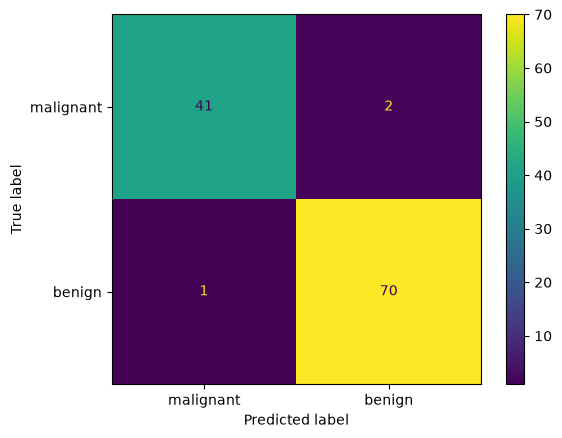

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot()
plt.show()

## Viva points

- Logistic Regression is a **classification** algorithm, even though the name says regression.
- Sigmoid: 1 / (1 + e^-z). It squeezes any number into the range 0 to 1.
- When the cost of a missed positive is high (like cancer), watch **Recall**.
- Accuracy alone is misleading when the classes are imbalanced.